# Archetypes, rules, and anomalies

**Name:** Raaj Banga

Clustering, association rules, and anomaly detection. Block 8 saves the archetypes for notebook 04.

## Part 1: Setup

### Block 1: Imports and paths

In [1]:
# python 3.14.10, pandas 2.3.3, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1, matplotlib 3.11.2, mlxtend 0.25.0
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mlxtend.frequent_patterns import association_rules, fpgrowth
from scipy.stats import chi2_contingency
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score, roc_auc_score, silhouette_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import LocalOutlierFactor

# Find the project folder whether this runs from notebooks/ or the project root
ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
from config import CRASHES, PROCESSED, SEED
from helpers import (FEATURES, make_model, model_columns, to_ranks, CRASH_COLORS, CRASH_LABELS, CRASH_SHORT, load_firms, save_figure, set_style)

set_style()
import warnings
warnings.filterwarnings("ignore", message=".*feature names.*")
ORDER = list(CRASHES)

### Block 2: Load the data

In [2]:
# One row per firm per crash, from 07_build_features.py
firms = load_firms()
print(firms.shape)
print(firms["crash"].value_counts().to_string())

(10513, 70)
crash
tariff_2025    3698
rates_2022     3599
covid_2020     3216


## Part 2: Clustering

### Block 3: Feature matrix for clustering

One clustering on all rows (decided 2026-11-08). Each feature is its percentile within its own crash, so an archetype means the same profile in every crash and crash-wide shifts (2022's higher momentum) don't split clusters. Missing values are set to 0.5, the middle. Percentiles are already on one scale, so no further scaling is needed.

In [3]:
ranked = to_ranks(firms)
X = ranked[FEATURES].fillna(0.5).values
print(X.shape, f"share of cells filled with 0.5: {ranked[FEATURES].isna().mean().mean():.1%}")

(10513, 16) share of cells filled with 0.5: 14.4%


### Block 4: k-means

k from 3 to 8 (two groups are too coarse to call archetypes). Silhouette on a 4,000-row sample, and stability as the mean adjusted Rand index between 10 seeds. Rule, set before looking: the k with the highest silhouette among those with stability of at least 0.8.

In [4]:
rng = np.random.default_rng(SEED)
sample = rng.choice(len(X), 4000, replace=False)
choice = []
for k in range(3, 9):
    fits = [KMeans(k, n_init=10, random_state=SEED + s).fit(X) for s in range(10)]
    labels_k = [f.labels_ for f in fits]
    ari = np.mean([adjusted_rand_score(labels_k[i], labels_k[j]) for i in range(10) for j in range(i + 1, 10)])
    choice.append({"k": k, "silhouette": silhouette_score(X[sample], labels_k[0][sample]),
                   "stability_ari": ari, "inertia": fits[0].inertia_})
choice = pd.DataFrame(choice).set_index("k")
print(choice.round(3).to_string())

stable = choice[choice["stability_ari"] >= 0.8]
K = int(stable["silhouette"].idxmax()) if len(stable) else int(choice["silhouette"].idxmax())
kmeans = KMeans(K, n_init=10, random_state=SEED).fit(X)
firms["archetype"] = kmeans.labels_
print(f"\nChosen k = {K}")
print(firms["archetype"].value_counts().sort_index().to_string())

   silhouette  stability_ari   inertia
k                                     
3       0.148          0.999  8351.765
4       0.134          0.990  7768.707
5       0.113          0.995  7392.826
6       0.105          0.963  7108.543
7       0.106          0.989  6854.003
8       0.106          0.975  6621.166

Chosen k = 3
archetype
0    2545
1    3621
2    4347


### Block 5: HDBSCAN

Available directly in scikit-learn.

In [5]:
# Density-based clusters on the same matrix, as a check on k-means
hdb = HDBSCAN(min_cluster_size=150, min_samples=25).fit(X)
firms["hdbscan"] = hdb.labels_
n_clusters = len(set(hdb.labels_) - {-1})
print(f"HDBSCAN: {n_clusters} clusters, {np.mean(hdb.labels_ == -1):.1%} of rows left as noise")
print(pd.crosstab(firms["archetype"], firms["hdbscan"]).to_string())
clustered = hdb.labels_ != -1
if n_clusters > 1:
    print(f"\nAgreement with k-means on clustered rows (adjusted Rand): "
          f"{adjusted_rand_score(firms['archetype'][clustered], hdb.labels_[clustered]):.3f}")

HDBSCAN: 2 clusters, 77.4% of rows left as noise
hdbscan      -1     0    1
archetype                 
0          2310   235    0
1          3292    53  276
2          2534  1813    0

Agreement with k-means on clustered rows (adjusted Rand): 0.553


### Block 6: Archetype profiles and recovery rates

Median percentile of each feature per archetype (0.5 = typical for its crash). Each archetype is named after its most distinctive features, then its recovery and beat-SPY rates are shown per crash.

A0: high-ROA, cash-generating, covers interest
A1: loss-making, cash-burning, low-ROA
A2: large, low current ratio, calm

                                                rows             recovered_12m               beat_market               financial share
crash                                           2020  2022  2025          2020   2022   2025        2020   2022   2025                
archetype                                                                                                                             
A0: high-ROA, cash-generating, covers interest   807   828   910         0.809  0.449  0.713       0.560  0.373  0.391            0.10
A1: loss-making, cash-burning, low-ROA          1079  1219  1323         0.774  0.274  0.610       0.576  0.191  0.341            0.06
A2: large, low current ratio, calm              1330  1552  1465         0.710  0.539  0.760       0.347  0.393  0.429            0.43


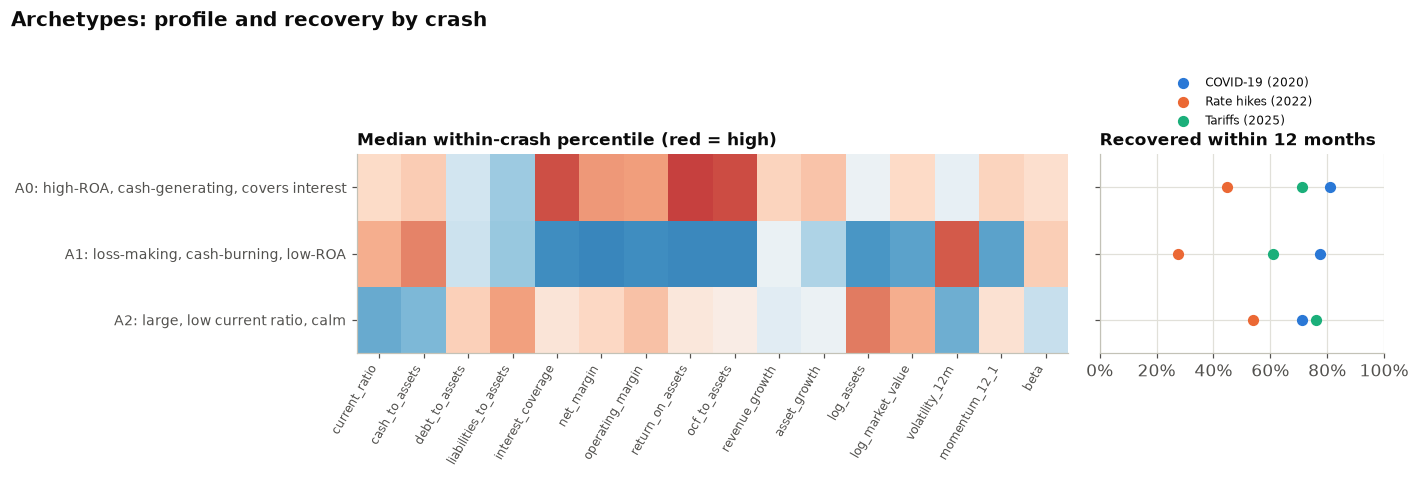

In [6]:
profile = ranked.assign(archetype=firms["archetype"]).groupby("archetype")[FEATURES].median()
SHORT = {"current_ratio": "high current ratio", "cash_to_assets": "cash-rich", "debt_to_assets": "indebted",
         "liabilities_to_assets": "leveraged", "interest_coverage": "covers interest",
         "net_margin": "profitable", "operating_margin": "high-margin", "return_on_assets": "high-ROA",
         "ocf_to_assets": "cash-generating", "revenue_growth": "growing sales",
         "asset_growth": "expanding", "log_assets": "large", "log_market_value": "high value",
         "volatility_12m": "volatile", "momentum_12_1": "rising", "beta": "high-beta"}
OPPOSITE = {"high current ratio": "low current ratio", "cash-rich": "cash-poor", "indebted": "low-debt", "leveraged": "low-leverage",
            "covers interest": "weak coverage", "profitable": "loss-making", "high-margin": "low-margin",
            "high-ROA": "low-ROA", "cash-generating": "cash-burning", "growing sales": "shrinking sales",
            "expanding": "shrinking", "large": "small", "high value": "low value", "volatile": "calm",
            "rising": "falling", "high-beta": "low-beta"}

def describe(row):
    dev = (row - 0.5).sort_values(key=abs, ascending=False).head(3)
    return ", ".join(SHORT[f] if v > 0 else OPPOSITE[SHORT[f]] for f, v in dev.items())

NAMES = {a: f"A{a}: {describe(profile.loc[a])}" for a in profile.index}
firms["archetype_name"] = firms["archetype"].map(NAMES)
for a, n in NAMES.items():
    print(n)

fin_share = firms.groupby("archetype")["is_financial"].mean()
rates = firms.pivot_table(index="archetype", columns="crash", values="recovered_12m", aggfunc="mean")[ORDER]
beat = firms.pivot_table(index="archetype", columns="crash", values="beat_market", aggfunc="mean")[ORDER]
sizes = pd.crosstab(firms["archetype"], firms["crash"])[ORDER]
summary = pd.concat({"rows": sizes, "recovered_12m": rates.round(3), "beat_market": beat.round(3)}, axis=1)
summary["financial share"] = fin_share.round(2)
summary.index = summary.index.map(NAMES)
print("\n" + summary.rename(columns=CRASH_SHORT, level=1).to_string())

# Figure: profile heatmap and recovery rate per crash
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 0.6 * K + 2.6), gridspec_kw={"width_ratios": [3, 1.2]})
ax1.imshow(profile.values, cmap="RdBu_r", vmin=0, vmax=1, aspect="auto")
ax1.set_xticks(range(len(FEATURES)), FEATURES, rotation=60, ha="right", fontsize=8)
ax1.set_yticks(range(K), [NAMES[a] for a in profile.index], fontsize=9)
ax1.grid(False)
ax1.set_title("Median within-crash percentile (red = high)", fontsize=11)
for j, crash in enumerate(ORDER):
    ax2.scatter(rates[crash].values, range(K), color=CRASH_COLORS[crash], label=CRASH_LABELS[crash], s=40, zorder=3)
ax2.set_yticks(range(K), [""] * K)
ax2.set_ylim(K - 0.5, -0.5)
ax2.set_xlim(0, 1)
ax2.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax2.grid(axis="x", color="#e1e0d9")
ax2.set_title("Recovered within 12 months", fontsize=11)
ax2.legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), ncol=1, fontsize=8)
fig.suptitle("Archetypes: profile and recovery by crash", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_figure(fig, "archetypes")
plt.show()

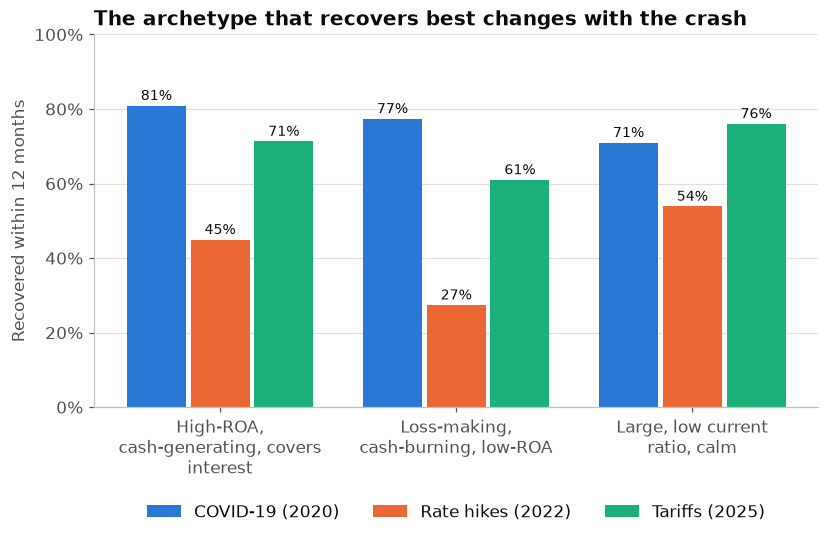

In [7]:
# Figure for the slides: recovery rate by archetype and crash
import textwrap
fig, ax = plt.subplots(figsize=(8.5, 4.4))
x = np.arange(K)
for j, crash in enumerate(ORDER):
    xs = x + (j - 1) * 0.27
    ax.bar(xs, rates[crash].values, 0.25, color=CRASH_COLORS[crash], label=CRASH_LABELS[crash])
    for xi, v in zip(xs, rates[crash].values):
        ax.text(xi, v + 0.015, f"{v:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, [textwrap.fill((n := NAMES[a].split(": ", 1)[1])[0].upper() + n[1:], 24, break_on_hyphens=False)
                 for a in rates.index])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylabel("Recovered within 12 months")
ax.set_title("The archetype that recovers best changes with the crash")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
save_figure(fig, "archetype_recovery")
plt.show()

### Block 7: Chi-square tests

1. Does recovery differ across archetypes, within each crash?
2. Does the mix of archetypes differ across crashes?
3. Does each archetype's recovery rate differ across crashes?

Cramér's V gives the size of each effect. Within a crash each firm appears once, so these tests have independent rows. Test 2 pools crashes, and firms repeat there, so treat its p-value as approximate.

In [8]:
def chi2(table):
    stat, p, dof, _ = chi2_contingency(table)
    v = np.sqrt(stat / (table.values.sum() * (min(table.shape) - 1)))
    return {"chi2": stat, "dof": dof, "p": p, "cramers_v": v}

tests = []
for crash in ORDER:
    d = firms[firms["crash"] == crash]
    for label in ["recovered_12m", "beat_market"]:
        tests.append({"test": f"{label} by archetype", "crash": CRASH_SHORT[crash],
                      **chi2(pd.crosstab(d["archetype"], d[label]))})
tests.append({"test": "archetype mix by crash", "crash": "all", **chi2(pd.crosstab(firms["archetype"], firms["crash"]))})
for a in sorted(firms["archetype"].unique()):
    d = firms[firms["archetype"] == a]
    tests.append({"test": f"recovered_12m by crash, {NAMES[a]}", "crash": "all",
                  **chi2(pd.crosstab(d["crash"], d["recovered_12m"]))})
tests = pd.DataFrame(tests)
print(tests.round(4).to_string(index=False))

                                                                  test crash     chi2  dof      p  cramers_v
                                            recovered_12m by archetype  2020  29.6583    2 0.0000     0.0960
                                              beat_market by archetype  2020 155.7447    2 0.0000     0.2201
                                            recovered_12m by archetype  2022 197.2014    2 0.0000     0.2341
                                              beat_market by archetype  2022 141.8157    2 0.0000     0.1985
                                            recovered_12m by archetype  2025  76.1021    2 0.0000     0.1435
                                              beat_market by archetype  2025  22.9449    2 0.0000     0.0788
                                                archetype mix by crash   all  11.8509    4 0.0185     0.0237
recovered_12m by crash, A0: high-ROA, cash-generating, covers interest   all 254.4771    2 0.0000     0.3162
        recovered_1

### Block 8: Save archetypes

Write firm, crash, and archetype to `data/processed/archetypes.parquet` for notebook 04.

In [9]:
out = firms[["cik", "crash", "archetype", "archetype_name"]]
out.to_parquet(PROCESSED / "archetypes.parquet", index=False)
print(f"Saved {len(out):,} rows to archetypes.parquet")

Saved 10,513 rows to archetypes.parquet


## Part 3: Association rules

### Block 9: Bin features

Each feature becomes low, mid, or high by within-crash tertile, so a bin means the same thing in every crash. Missing values get no item. Sector is an item too. The outcomes are `recovered` and `not_recovered` (decided 2026-11-08). Bankruptcy has only 91 rows, too few for rules, so it gets a side table in Block 11.

In [10]:
items = {}
for f in FEATURES:
    bins = ranked[f].apply(lambda v: np.nan if np.isnan(v) else ("low" if v <= 1 / 3 else "mid" if v <= 2 / 3 else "high"))
    for b in ["low", "high"]:  # mid bins are uninformative and slow FP-Growth down
        items[f"{f}={b}"] = bins == b
for sector in firms["sic_division"].unique():
    items[f"sector={sector}"] = firms["sic_division"] == sector
items["recovered"] = firms["recovered_12m"] == 1
items["not_recovered"] = firms["recovered_12m"] == 0
basket = pd.DataFrame(items).fillna(False).astype(bool)
basket["crash"] = firms["crash"].values
print(basket.shape)

(10513, 44)


### Block 10: FP-Growth

Run per crash. Minimum support 5%, up to three conditions plus the outcome. Only rules whose result is exactly `recovered` or `not_recovered` are kept, and lift must be at least 1.1.

In [11]:
OUTCOMES = {"recovered", "not_recovered"}
rules = {}
for crash in ORDER:
    b = basket[basket["crash"] == crash].drop(columns="crash")
    freq = fpgrowth(b, min_support=0.05, use_colnames=True, max_len=4)
    r = association_rules(freq, metric="lift", min_threshold=1.1)
    r = r[r["consequents"].apply(lambda s: len(s) == 1 and next(iter(s)) in OUTCOMES)
          & r["antecedents"].apply(lambda s: not (s & OUTCOMES))]
    r = r.assign(rule=r["antecedents"].apply(lambda s: " & ".join(sorted(s))),
                 outcome=r["consequents"].apply(lambda s: next(iter(s))))
    rules[crash] = r[["rule", "outcome", "support", "confidence", "lift"]].sort_values("lift", ascending=False)
    print(f"{CRASH_LABELS[crash]}: {len(r):,} rules "
          f"({(r['outcome'] == 'recovered').sum():,} to recovered, {(r['outcome'] == 'not_recovered').sum():,} to not recovered)")
    for outcome in ["recovered", "not_recovered"]:
        top = rules[crash][rules[crash]["outcome"] == outcome].head(5)
        print(f"  Top 5 by lift, {outcome}:")
        print(top.round(3).to_string(index=False))

COVID-19 (2020): 91 rules (76 to recovered, 15 to not recovered)
  Top 5 by lift, recovered:
                                                          rule   outcome  support  confidence  lift
                   cash_to_assets=high & log_market_value=high recovered    0.058       0.908 1.200
                         cash_to_assets=high & sector=Services recovered    0.058       0.891 1.178
 asset_growth=high & cash_to_assets=high & revenue_growth=high recovered    0.058       0.890 1.178
net_margin=high & operating_margin=high & sector=Manufacturing recovered    0.057       0.884 1.169
           asset_growth=high & beta=high & revenue_growth=high recovered    0.051       0.882 1.167
  Top 5 by lift, not_recovered:
                                   rule       outcome  support  confidence  lift
          beta=low & volatility_12m=low not_recovered    0.071       0.446 1.828
          beta=low & cash_to_assets=low not_recovered    0.059       0.411 1.685
cash_to_assets=low & volatility_

Rate hikes (2022): 640 rules (100 to recovered, 540 to not recovered)
  Top 5 by lift, recovered:
                                                             rule   outcome  support  confidence  lift
                           current_ratio=low & volatility_12m=low recovered    0.060       0.658 1.535
      current_ratio=low & log_assets=high & log_market_value=high recovered    0.060       0.639 1.492
                          cash_to_assets=low & ocf_to_assets=high recovered    0.064       0.632 1.475
                              current_ratio=low & log_assets=high recovered    0.074       0.622 1.452
liabilities_to_assets=high & log_assets=high & volatility_12m=low recovered    0.064       0.609 1.421
  Top 5 by lift, not_recovered:
                                                                rule       outcome  support  confidence  lift
      asset_growth=high & liabilities_to_assets=low & net_margin=low not_recovered    0.051       0.876 1.533
asset_growth=high & liabilities_

Tariffs (2025): 326 rules (198 to recovered, 128 to not recovered)
  Top 5 by lift, recovered:
                                                                rule   outcome  support  confidence  lift
       liabilities_to_assets=high & log_assets=high & sector=Finance recovered    0.074       0.877 1.263
    liabilities_to_assets=high & sector=Finance & volatility_12m=low recovered    0.069       0.874 1.257
cash_to_assets=low & liabilities_to_assets=high & volatility_12m=low recovered    0.054       0.868 1.250
           cash_to_assets=low & net_margin=high & volatility_12m=low recovered    0.060       0.868 1.249
                                    log_assets=high & sector=Finance recovered    0.101       0.856 1.231
  Top 5 by lift, not_recovered:
                                                        rule       outcome  support  confidence  lift
                                             sector=Services not_recovered    0.079       0.452 1.481
log_market_value=low & net_margin

### Block 11: Rank by lift and compare across crashes

Each crash's top 10 rules per outcome are rechecked in the other two crashes: their lift there, on the same within-crash bins. A rule "holds" in a crash if its lift there is at least 1.1. Then a side table of bankruptcy rates for the bins that matter most.

In [12]:
def lift_in(crash, rule, outcome):
    b = basket[basket["crash"] == crash]
    has = np.logical_and.reduce([b[i] for i in rule.split(" & ")])
    if has.sum() == 0:
        return np.nan
    return b.loc[has, outcome].mean() / b[outcome].mean()

rows = []
for crash in ORDER:
    for outcome in ["recovered", "not_recovered"]:
        for r in rules[crash][rules[crash]["outcome"] == outcome].head(10).itertuples():
            lifts = {CRASH_SHORT[c]: lift_in(c, r.rule, outcome) for c in ORDER}
            rows.append({"found in": CRASH_SHORT[crash], "rule": r.rule, "outcome": outcome, **lifts,
                         "holds in": sum(v >= 1.1 for v in lifts.values()),
                         "reverses in": sum(v < 0.9 for v in lifts.values())})
compare = pd.DataFrame(rows).drop_duplicates(["rule", "outcome"])
pd.set_option("display.max_colwidth", 80)
print(compare.round(2).to_string(index=False))
print("\nTop rules by number of crashes where they hold (lift >= 1.1):")
print(compare.groupby("outcome")["holds in"].value_counts().unstack(fill_value=0).to_string())
print(f"\nTop rules that reverse (lift < 0.9) in at least one other crash: {(compare['reverses in'] > 0).sum()} of {len(compare)}")

# Side table: bankruptcy rate by tertile of the features most linked to failure
failed = firms["exit_status"] == "failed"
side = []
for f in ["volatility_12m", "liabilities_to_assets", "cash_to_assets", "return_on_assets", "log_market_value"]:
    for b in ["low", "high"]:
        has = basket[f"{f}={b}"]
        side.append({"bin": f"{f}={b}", **{CRASH_SHORT[c]: failed[has & (firms["crash"] == c)].mean() for c in ORDER}})
side = pd.DataFrame(side).set_index("bin")
print("\nShare of firms that failed (bankruptcy then delisting), by bin; overall:",
      {CRASH_SHORT[c]: round(failed[firms["crash"] == c].mean(), 3) for c in ORDER})
print((side * 100).round(1).to_string())

found in                                                                 rule       outcome  2020  2022  2025  holds in  reverses in
    2020                          cash_to_assets=high & log_market_value=high     recovered  1.20  0.75  1.06         1            1
    2020                                cash_to_assets=high & sector=Services     recovered  1.18  0.58  0.76         1            2
    2020        asset_growth=high & cash_to_assets=high & revenue_growth=high     recovered  1.18  0.44  0.95         1            1
    2020       net_margin=high & operating_margin=high & sector=Manufacturing     recovered  1.17  1.13  1.11         3            0
    2020                  asset_growth=high & beta=high & revenue_growth=high     recovered  1.17  0.55  0.98         1            1
    2020             beta=high & return_on_assets=high & sector=Manufacturing     recovered  1.16  1.01  1.11         2            0
    2020    ocf_to_assets=high & operating_margin=high & sector=Manuf

## Part 4: Anomaly detection

### Block 12: Isolation Forest

On the same percentile matrix as the clusters, so an anomaly is a firm with an unusual combination of features for its crash. The top 2% are flagged.

In [13]:
iso = IsolationForest(n_estimators=500, contamination=0.02, random_state=SEED).fit(X)
firms["iso_score"] = -iso.score_samples(X)  # higher = more unusual
firms["iso_flag"] = iso.predict(X) == -1
print(f"Isolation Forest flags {firms['iso_flag'].sum()} rows")
print(firms.groupby("iso_flag")[["recovered_12m", "beat_market", "extreme_move", "split_flagged"]].mean().round(3).to_string())
print("\nFlagged rows by crash and archetype:")
print(pd.crosstab(firms.loc[firms["iso_flag"], "archetype_name"], firms.loc[firms["iso_flag"], "crash"]).to_string())

Isolation Forest flags 211 rows
          recovered_12m  beat_market  extreme_move  split_flagged
iso_flag                                                         
False             0.625        0.394         0.029          0.021
True              0.488        0.318         0.128          0.100

Flagged rows by crash and archetype:
crash                                           covid_2020  rates_2022  tariff_2025
archetype_name                                                                     
A0: high-ROA, cash-generating, covers interest          16          17           11
A1: loss-making, cash-burning, low-ROA                  48          48           59
A2: large, low current ratio, calm                       2           7            3


### Block 13: LOF

First to drop if time runs short; keep Isolation Forest.

In [14]:
lof = LocalOutlierFactor(n_neighbors=35, contamination=0.02)
firms["lof_flag"] = lof.fit_predict(X) == -1
firms["lof_score"] = -lof.negative_outlier_factor_
both = firms["iso_flag"] & firms["lof_flag"]
print(f"LOF flags {firms['lof_flag'].sum()} rows; {both.sum()} flagged by both "
      f"(Jaccard {both.sum() / (firms['iso_flag'] | firms['lof_flag']).sum():.2f})")
print(firms.groupby("lof_flag")[["recovered_12m", "beat_market"]].mean().round(3).to_string())

LOF flags 211 rows; 32 flagged by both (Jaccard 0.08)
          recovered_12m  beat_market
lof_flag                            
False             0.623        0.393
True              0.597        0.355


### Block 14: Firms that beat or broke the odds

Odds come from out-of-fold LightGBM predictions within each crash (the same model as notebook 02). "Beat the odds": recovered despite a predicted chance in the bottom 10% of its crash. "Broke the odds": didn't recover despite a top-10% predicted chance. Anomaly flags from Blocks 12 and 13 are shown alongside.

In [15]:
FULL, _ = model_columns(firms)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
firms["p_recover"] = np.nan
for crash in ORDER:
    idx = firms.index[firms["crash"] == crash]
    d = firms.loc[idx]
    for train, test in cv.split(d, d["recovered_12m"], groups=d["cik"]):
        m = make_model("lgbm", FULL).fit(d.iloc[train], d["recovered_12m"].iloc[train])
        firms.loc[idx[test], "p_recover"] = m.predict_proba(d.iloc[test])[:, 1]
print("Out-of-fold AUC per crash:",
      {CRASH_SHORT[c]: round(roc_auc_score(g["recovered_12m"], g["p_recover"]), 3) for c, g in firms.groupby("crash")})

pct = firms.groupby("crash")["p_recover"].rank(pct=True)
firms["odds"] = np.where((pct <= 0.1) & (firms["recovered_12m"] == 1), "beat the odds",
                np.where((pct >= 0.9) & (firms["recovered_12m"] == 0), "broke the odds", ""))
print(pd.crosstab(firms["odds"], firms["crash"]).rename(columns=CRASH_SHORT).to_string())
print("\nShare that are also anomalies, and data-quality flags:")
print(firms[firms["odds"] != ""].groupby("odds")[["iso_flag", "lof_flag", "extreme_move", "split_flagged", "is_financial"]]
      .mean().round(3).to_string())
print("\nExit status:")
print(pd.crosstab(firms.loc[firms["odds"] != "", "odds"], firms.loc[firms["odds"] != "", "exit_status"]).to_string())

Out-of-fold AUC per crash: {'2020': 0.678, '2022': 0.703, '2025': 0.674}
crash           2020  2022  2025
odds                            
                3048  3458  3488
beat the odds    142    54   174
broke the odds    26    87    36

Share that are also anomalies, and data-quality flags:
                iso_flag  lof_flag  extreme_move  split_flagged  is_financial
odds                                                                         
beat the odds      0.068     0.019         0.049          0.035         0.230
broke the odds     0.007     0.020         0.020          0.007         0.221

Exit status:
exit_status     acquired  delisted_other  failed  none
odds                                                  
beat the odds         13               0       1   356
broke the odds        10               2       1   136


### Block 15: Case checks

The firms with the lowest predicted chance that recovered, and the highest that didn't, plus every row that is both an anomaly and an odds case. Each is checked for signs of a data error (a remaining 3x move, an unconfirmed split, or a removed spike) before it's read as a real story.

In [16]:
cols = ["name", "ticker", "crash", "archetype_name", "p_recover", "drawdown", "firm_return",
        "exit_status", "extreme_move", "split_flagged", "spikes_removed", "iso_flag"]
show = lambda d: d[cols].assign(crash=d["crash"].map(CRASH_SHORT)).round(3).to_string(index=False)
beat_odds = firms[firms["odds"] == "beat the odds"].nsmallest(8, "p_recover")
broke_odds = firms[firms["odds"] == "broke the odds"].nlargest(8, "p_recover")
print("Beat the odds (lowest predicted chance, recovered):\n" + show(beat_odds))
print("\nBroke the odds (highest predicted chance, didn't recover):\n" + show(broke_odds))
flag_cols = ["extreme_move", "split_flagged"]
odd = firms[firms["odds"] != ""]
print(f"\nOdds cases with a data-quality flag: {odd[flag_cols].any(axis=1).mean():.1%} "
      f"vs {firms[flag_cols].any(axis=1).mean():.1%} of all rows")
both = firms[(firms["odds"] != "") & firms["iso_flag"]]
print(f"\nOdds cases that are also Isolation Forest anomalies ({len(both)}):\n" + show(both))

Beat the odds (lowest predicted chance, recovered):
                                name ticker crash                         archetype_name  p_recover  drawdown  firm_return exit_status  extreme_move  split_flagged  spikes_removed  iso_flag
              AppTech Payments Corp.   APCX  2022 A1: loss-making, cash-burning, low-ROA      0.033    -0.790        0.967        none         False          False               0      True
  GLOBAL TECH INDUSTRIES GROUP, INC.   GTII  2022 A1: loss-making, cash-burning, low-ROA      0.053    -0.787       -0.493        none         False          False               1      True
       LMP Automotive Holdings, Inc.   LMPX  2022 A1: loss-making, cash-burning, low-ROA      0.057    -0.692        2.283        none          True          False               1     False
  NEUROONE MEDICAL TECHNOLOGIES Corp   NMTC  2022 A1: loss-making, cash-burning, low-ROA      0.060    -0.796       -0.567        none         False          False               0     Fals

## Part 5: Notes for the report

Numbers are from the 2026-11-09 rerun, after the audit fixes (Task 5b). Archetype numbers changed in that rerun, so refer to them by name.

**Archetypes (Blocks 3 to 8)**
- k = 3 by the rule set in advance (silhouette 0.15, stability 0.999). Silhouette falls as k grows, so the groups are broad tendencies, not sharp clusters. Say so.
- HDBSCAN finds little dense structure (77% noise, 2 clusters), which agrees: firms form a continuum.
- The three archetypes: profitable and cash-generating (A0, 2,545 rows), loss-making and cash-burning (A1, 4,347), large and calm with a low current ratio, 43% financial (A2, 3,621). "Low current ratio" is the balance-sheet ratio, not trading liquidity.
- Recovery by archetype changes order across crashes. Loss-making firms recovered 77% in 2020 (near the top) but 27% in 2022 (far the lowest). Large, calm firms were lowest in 2020 (71%) and highest in 2022 and 2025 (54%, 76%).
- Chi-square: recovery differs by archetype in every crash (Cramér's V 0.10 to 0.23), and each archetype's recovery differs across crashes (V 0.21 to 0.41). The archetype mix barely changes across crashes (V 0.02). Same kinds of firms, different winners.

**Rules (Blocks 9 to 11)**
- 91 / 640 / 326 rules (2020 / 2022 / 2025). Only a few hold in all three crashes: profitable, cash-generating manufacturers recover (lift 1.11 to 1.17), and low momentum with low margins doesn't (1.14 to 1.44).
- 2020's not-recovered rules (low beta, low volatility, low cash, financials) reverse in 2022 and 2025 (lift 0.56 to 0.90). This is the same volatility reversal as in notebook 02.

**Anomalies and odds (Blocks 12 to 15)**
- Isolation Forest flags 211 rows, mostly loss-making firms; they recover less (49% vs 63%) and 13% have a remaining 3x move, so many are data-quality cases, not stories.
- LOF and Isolation Forest barely agree (Jaccard 0.08). LOF flags local oddities with normal recovery rates.
- "Beat the odds" cases (370) are mostly 2020 and 2025; "broke the odds" cases (149) are mostly 2022 and include large, calm firms (Costco, Church & Dwight, Aon, General Mills in 2025), which barely fell and then drifted.
- Check any single case by hand before using it in the report.